# Jak komputer czyta tekst? Laboratorium NLP

Ćwiczenia do prezentacji **„Jak ChatGPT nauczył się języka?”**. Przy każdym doświadczeniu najpierw przewidź wynik, potem uruchom komórkę i wyjaśnij, skąd wziął się rezultat.

**Na lekcji:** uruchom „Start”, a potem wybrane sekcje od góry. Na szybki pokaz wybierz **1 → 5 → 6 → 8 → 9**. W panelu **Spis treści** po lewej możesz przeskakiwać między tematami. Komórki z polami do edycji pozwalają podmieniać przykłady bez zmiany reszty kodu.

**Pierwsze uruchomienie** potrzebuje internetu do pobrania bibliotek i wag. Wystarczy zwykły procesor. Wagi pobierają się przy pierwszym uruchomieniu komórki danego modelu. Jeśli pokazujesz wszystkie modele, uruchom notebook przed lekcją (łącznie ok. 800 MB pobierania). Gotowe wyniki pod komórkami można też obejrzeć bez uruchamiania.

In [4]:
# @title Start · biblioteki i ustawienia
%pip -q install "nltk>=3.9,<4" "tiktoken>=0.9,<1" "gensim>=4.4,<5" "transformers>=4.51,<5"
from collections import Counter
from functools import lru_cache
from hashlib import sha256
from math import log
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import re
from shutil import copyfileobj

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
TEAL, AMBER, BLUE = "#007e73", "#bc720d", "#285394"
pd.options.display.float_format = "{:.3f}".format
CACHE = Path("nlp_demo_cache")
CACHE.mkdir(exist_ok=True)

def words(text):
    """Słowa zapisane małymi literami, bez interpunkcji."""
    return re.findall(r"[^\W\d_]+", text.casefold())

def download(url, filename, expected_hash=None):
    """Pobiera plik raz na sesję. Nie zapisuje częściowego pobrania jako gotowego pliku."""
    target = CACHE / filename
    if target.exists() and (expected_hash is None or sha256(target.read_bytes()).hexdigest() == expected_hash):
        return target
    print(f"Pobieram {filename}…")
    with urlopen(url, timeout=60) as response:
        data = response.read()
    if expected_hash and sha256(data).hexdigest() != expected_hash:
        raise ValueError(f"Plik {filename} ma inną sumę SHA-256 niż oczekiwano.")
    pending = target.with_suffix(".part")
    pending.write_bytes(data)
    pending.replace(target)
    return target

## 1. Kontekst i tokenizacja

**Slajdy 2–4.** „Zwiedziliśmy zamek” i „W drzwiach zaciął się zamek”. Co podpowiedziało ci znaczenie? A ile tokenów ma zapis `2 + 2 = 4`? Przewidź wynik dla obu kodowań.

Token może zawierać spację lub część znaku zapisanego w UTF‑8. Tabela pokazuje granice i identyfikatory tokenów. W razie podziału wewnątrz znaku pokazuje bajty.

In [5]:
# @title Tokenizatory · podmień tekst i uruchom
import tiktoken

tekst = "2 + 2 = 4" # @param {type:"string"}
tekst_polski = "Zażółć gęślą jaźń" # @param {type:"string"}

def token_rows(text, encoding_name):
    tokenizer = tiktoken.get_encoding(encoding_name)
    rows = []
    for token_id in tokenizer.encode(text, disallowed_special=()):
        raw = tokenizer.decode_single_token_bytes(token_id)
        try:
            piece = raw.decode("utf-8").replace(" ", "␣")
        except UnicodeDecodeError:
            piece = "bajty " + raw.hex(" ")
        rows.append({"Fragment": piece, "ID": str(token_id)})
    return pd.DataFrame(rows, columns=["Fragment", "ID"])

for example in (tekst, tekst_polski):
    print(repr(example))
    tables = {name: token_rows(example, name) for name in ("r50k_base", "o200k_base")}
    print("   ".join(f"{name}: {len(table)}" for name, table in tables.items()))
    display(pd.concat(tables, axis=1).fillna(""))

'2 + 2 = 4'
r50k_base: 5   o200k_base: 7


r50k_base       o200k_base     
   Fragment    ID   Fragment   ID
0         2    17          2   17
1        ␣+  1343         ␣+  659
2        ␣2   362          ␣  220
3        ␣=   796          2   17
4        ␣4   604         ␣=  314
5                          ␣  220
6                          4   19

'Zażółć gęślą jaźń'
r50k_base: 20   o200k_base: 11


r50k_base        o200k_base       
    Fragment     ID   Fragment     ID
0          Z     57         Za  55302
1          a     64          ż   1777
2   bajty c5    129         ół  42107
3   bajty bc    120          ć   1187
4          ó  10205         ␣g    329
5          ł  41615          ę   1580
6          ć  38325         śl  87789
7         ␣g    308          ą   1624
8   bajty c4    128        ␣ja   3165
9   bajty 99    247          ź  13852
10  bajty c5    129          ń   6316
11  bajty 9b    249                  
12         l     75                  
13  bajty c4    128                  
14  bajty 85    227                  
15       ␣ja  45091                  
16  bajty c5    129                  
17  bajty ba    118                  
18  bajty c5    129                  
19  bajty 84    226

**Sprawdź:** porównaj „Zażółć gęślą jaźń” z „Zazolc gesla jazn”. Czy usunięcie znaków diakrytycznych zmienia liczbę lub granice tokenów?

## 2. Stemming i lematyzacja

**Slajd 5.** Jak policzyć „kotami” i „kotów” jako wystąpienia tego samego słowa? Dla angielskiego uruchomimy stemmer Portera. Dla polskiego użyjemy małego słownika form z lekcji, aby dokładnie zobaczyć regułę. Pełny lematyzator potrzebuje większego słownika i często kontekstu.

In [6]:
# @title Stemming i mały słownik form
from nltk.stem import PorterStemmer

porter = PorterStemmer(mode=PorterStemmer.ORIGINAL_ALGORITHM)
LEMMAS = {
    "kotami": "kot", "kotów": "kot", "kotem": "kot", "koty": "kot",
    "psa": "pies", "pogryzł": "pogryźć", "człowieka": "człowiek",
    "alę": "ala", "olę": "ola",
}

def lemmas(text):
    return [LEMMAS.get(word, word) for word in words(text)]

english_forms = ["study", "studies", "studying", "played", "playing"]
polish_forms = ["kot", "kotami", "kotów", "kotem", "koty"]
display(pd.DataFrame({"Forma EN": english_forms, "Wynik stemmera": [porter.stem(w) for w in english_forms],
                      "Forma PL": polish_forms, "Lemat ze słownika": [lemmas(w)[0] for w in polish_forms]}))

,Forma EN,Wynik stemmera,Forma PL,Lemat ze słownika
0,study,studi,kot,kot
1,studies,studi,kotami,kot
2,studying,studi,kotów,kot
3,played,plai,kotem,kot
4,playing,plai,koty,kot


## 3. Prawo Zipfa na prawdziwym tekście

**Slajd 6.** Które słowa obstawiasz w pierwszej piątce „Pana Tadeusza”? Liczymy wszystkie formy słów. Na wykresie log–log porównujemy częstości z linią `f(1)/r`, gdzie `r` to miejsce w rankingu. Linia stanowi punkt odniesienia, a rozkład zależy od tekstu i sposobu liczenia.

Al-Kindi wykorzystywał częstość **liter** do analizy szyfrów. Tu liczymy częstość **słów**.

Pobieram pan-tadeusz.txt…
Liczba słów: 68,202. Różnych form: 18,766.


,Słowo,Wystąpienia
0,i,2128
1,w,1694
2,się,1497
3,z,1384
4,na,1305
5,nie,938
6,jak,578
7,do,565


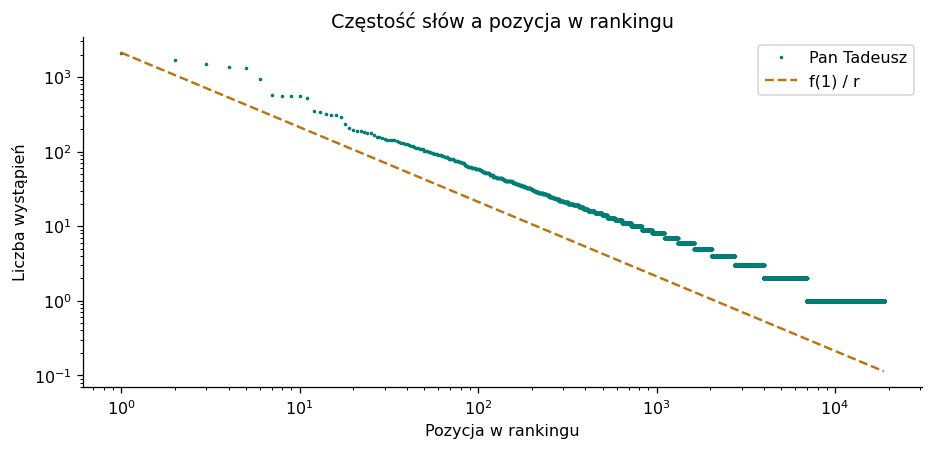

In [7]:
# @title Policz słowa w „Panu Tadeuszu”
book = download("https://wolnelektury.pl/media/book/txt/pan-tadeusz.txt", "pan-tadeusz.txt")
text = book.read_text(encoding="utf-8-sig")
# Plik Wolnych Lektur ma na końcu informacje redakcyjne.
text = re.split(r"(?im)^\s*-{4,}\s*$|^\s*Ta lektura, podobnie jak tysiące innych", text, maxsplit=1)[0]
counts = Counter(words(text))
top = counts.most_common()
print(f"Liczba słów: {sum(counts.values()):,}. Różnych form: {len(counts):,}.")
display(pd.DataFrame(top[:8], columns=["Słowo", "Wystąpienia"]))
ranks = np.arange(1, len(top) + 1)
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
ax.loglog(ranks, [n for _, n in top], ".", ms=2.5, color=TEAL, label="Pan Tadeusz")
ax.loglog(ranks, top[0][1] / ranks, "--", color=AMBER, label="f(1) / r")
ax.set(xlabel="Pozycja w rankingu", ylabel="Liczba wystąpień", title="Częstość słów a pozycja w rankingu")
ax.legend()
plt.show()

## 4. Bag-of-Words i bigramy

**Slajdy 7, 10 i 19.** Porównaj „Pies pogryzł człowieka” z „Człowiek pogryzł psa”. Obstaw, przy którym sposobie liczenia wiersze będą równe. Potem wpisz własną parę. Jeśli potrzebujesz dodatkowych lematów, dodaj je do słownika w sekcji 2.

In [8]:
# @title Porównaj dwa zdania
zdanie_a = "Pies pogryzł człowieka." # @param {type:"string"}
zdanie_b = "Człowiek pogryzł psa." # @param {type:"string"}
sentences = [zdanie_a, zdanie_b]
forms = [words(sentence) for sentence in sentences]
normalized = [lemmas(sentence) for sentence in sentences]

def feature_table(sequences, bigrams=False):
    rows = []
    for sequence in sequences:
        features = (" ".join(pair) for pair in zip(sequence, sequence[1:])) if bigrams else sequence
        rows.append(Counter(features))
    return pd.DataFrame(rows, index=["A", "B"]).fillna(0).astype(int).sort_index(axis=1)

for label, table in [
    ("Słowa przed lematyzacją", feature_table(forms)),
    ("Lematy", feature_table(normalized)),
    ("Bigramy lematów", feature_table(normalized, bigrams=True)),
]:
    print(f"{label} — wektory równe: {'tak' if table.iloc[0].equals(table.iloc[1]) else 'nie'}")
    display(table)

Słowa przed lematyzacją — wektory równe: nie


,człowiek,człowieka,pies,pogryzł,psa
A,0,1,1,1,0
B,1,0,0,1,1


Lematy — wektory równe: tak


,człowiek,pies,pogryźć
A,1,1,1
B,1,1,1


Bigramy lematów — wektory równe: nie


,człowiek pogryźć,pies pogryźć,pogryźć człowiek,pogryźć pies
A,0,1,1,0
B,1,0,0,1


**Wyzwanie olimpijskie:** znajdź dwie różne sekwencje o tych samych licznikach bigramów. Wskazówka: zacznij od `a b a c a`.

## 5. TF‑IDF i wyszukiwarka

**Slajdy 8–9.** „Sigma” występuje w 2 z 20 dokumentów. Co się stanie z IDF, jeśli słowo pojawi się w większej liczbie dokumentów z tego samego zbioru? Użyj suwaka. Tu liczymy wygładzony IDF zgodny z domyślnym scikit-learn. W wyszukiwarce scikit-learn dodatkowo normalizuje wektory.

„Sigma” w 11/20 dokumentach → IDF = 1.56
Gdy TF = 3, iloczyn przed normalizacją wynosi 4.68.


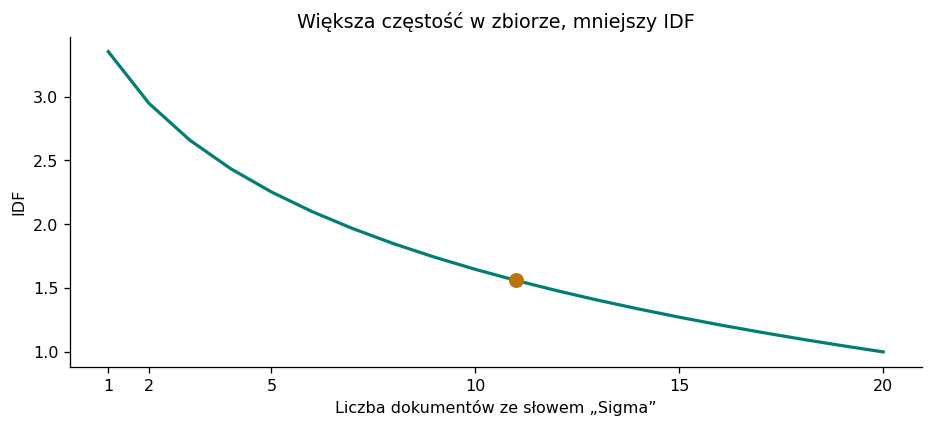

In [22]:
# @title Sigma · zmień liczbę dokumentów ze słowem
dokumenty_ze_slowem = 11 # @param {type:"slider", min:1, max:20, step:1}
N = 20
dfs = np.arange(1, N + 1)
values = 1 + np.log((1 + N) / (1 + dfs))
selected_idf = 1 + log((1 + N) / (1 + dokumenty_ze_slowem))
print(f"„Sigma” w {dokumenty_ze_slowem}/{N} dokumentach → IDF = {selected_idf:.2f}")
print(f"Gdy TF = 3, iloczyn przed normalizacją wynosi {3 * selected_idf:.2f}.")
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
ax.plot(dfs, values, color=TEAL, lw=2)
ax.scatter(dokumenty_ze_slowem, selected_idf, color=AMBER, s=70, zorder=3)
ax.set(xlabel="Liczba dokumentów ze słowem „Sigma”", ylabel="IDF",
       title="Większa częstość w zbiorze, mniejszy IDF")
ax.set_xticks([1, 2, 5, 10, 15, 20])
plt.show()

**Głosowanie:** czy „samochód elektryczny” i „auto na prąd” znajdą ten sam dokument? Porównaj ranking przed i po prostej zamianie synonimów.

In [10]:
# @title Wyszukiwarka · sprawdź dwa zapytania
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

docs = [
    "Samochód elektryczny ma baterię.",
    "Zamek góruje nad miastem.",
    "Kot śpi obok psa.",
]
zapytanie = "auto na prąd" # @param {type:"string"}
zamien_synonimy = False # @param {type:"boolean"}
vectorizer = TfidfVectorizer()
doc_vectors = vectorizer.fit_transform(docs)

def search(query, rewrite=False):
    if rewrite:
        query = re.sub(r"\bauto\s+na\s+prąd\b", "samochód elektryczny", query, flags=re.IGNORECASE)
    query_vector = vectorizer.transform([query])
    scores = cosine_similarity(query_vector, doc_vectors)[0]
    result = pd.DataFrame({"Dokument": docs, "Podobieństwo": scores})
    return query, result.sort_values("Podobieństwo", ascending=False, kind="stable")

for query in ("samochód elektryczny", zapytanie):
    used_query, ranking = search(query, zamien_synonimy)
    print(f"{query!r} → wyszukuję {used_query!r}")
    display(ranking)

'samochód elektryczny' → wyszukuję 'samochód elektryczny'


,Dokument,Podobieństwo
0,Samochód elektryczny ma baterię.,0.707
1,Zamek góruje nad miastem.,0.000
2,Kot śpi obok psa.,0.000


'auto na prąd' → wyszukuję 'auto na prąd'


,Dokument,Podobieństwo
0,Samochód elektryczny ma baterię.,0.000
1,Zamek góruje nad miastem.,0.000
2,Kot śpi obok psa.,0.000


## 6. Gotowe Word2Vec i GloVe

**Slajdy 11–12.** Pobieramy angielskie wagi: próbkę Word2Vec z Google News udostępnioną przez NLTK (49 MB, 300 wymiarów) oraz GloVe z Wikipedii i Gigaword (69 MB, 50 wymiarów). Oba modele dają słowom **statyczne wektory**, wyuczone różnymi metodami i na innych tekstach.

Najpierw obstaw, czy `cat` będzie bliżej `dog` niż `car`. Potem porównaj najbliższe słowa i sprawdź hipotezę `king − man + woman ≈ queen`.

In [11]:
# @title Wczytaj wagi Word2Vec i GloVe
from gensim.models import KeyedVectors

@lru_cache(maxsize=1)
def load_word2vec():
    archive = download(
        "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages/models/word2vec_sample.zip",
        "word2vec_sample.zip",
        "d29ff84a6ceca407f8578648568c55894dac34641ceb1fa02f920264fe326b43",
    )
    vectors = CACHE / "pruned.word2vec.txt"
    if not vectors.exists():
        pending = vectors.with_suffix(".part")
        with ZipFile(archive) as zipped:
            with zipped.open("word2vec_sample/pruned.word2vec.txt") as source, pending.open("wb") as target:
                copyfileobj(source, target)
        pending.replace(vectors)
    return KeyedVectors.load_word2vec_format(str(vectors), binary=False)

@lru_cache(maxsize=1)
def load_glove():
    archive = download(
        "https://github.com/piskvorky/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz",
        "glove-wiki-gigaword-50.gz",
        "5c55f98957aa9fed8d2ac5fb1dcff57af3b23c5a3ee7af3f7945f8d49198eb24",
    )
    return KeyedVectors.load_word2vec_format(str(archive), binary=False)

word2vec = load_word2vec()
glove = load_glove()
embeddings = {"Word2Vec": word2vec, "GloVe": glove}
for label, vectors in embeddings.items():
    print(f"{label}: {len(vectors):,} wpisów, {vectors.vector_size} wymiarów.")

Pobieram word2vec_sample.zip…
Pobieram glove-wiki-gigaword-50.gz…
Word2Vec: 43,981 wpisów, 300 wymiarów.
GloVe: 400,000 wpisów, 50 wymiarów.


In [27]:
# @title Wektory · sąsiedzi, podobieństwo i analogia
slowo = "cat" # @param {type:"string"}
dodaj_1 = "king" # @param {type:"string"}
odejmij = "man" # @param {type:"string"}
dodaj_2 = "woman" # @param {type:"string"}
for label, vectors in embeddings.items():
    print(label)
    if slowo in vectors:
        print(f"Pierwszych 6 liczb wektora {slowo!r}: {np.round(vectors[slowo][:6], 3)}")
        display(pd.DataFrame(vectors.most_similar(slowo, topn=5), columns=["Sąsiad", "Kosinus"]))
    else:
        print(f"Brak {slowo!r} w słowniku. Sprawdź pisownię i wielkość liter.")
    print(f"cos(cat, dog) = {vectors.similarity('cat', 'dog'):.3f}")
    print(f"cos(cat, car) = {vectors.similarity('cat', 'car'):.3f}")
    print("king:", np.round(vectors[dodaj_1][:5], 3), "man:", np.round(vectors[odejmij][:5], 3), "women:", np.round(vectors[dodaj_2][:5], 3))
    missing = [word for word in (dodaj_1, odejmij, dodaj_2) if word not in vectors]
    if missing:
        print("Brak w słowniku:", ", ".join(missing))
    else:
        result = vectors.most_similar(positive=[dodaj_1, dodaj_2], negative=[odejmij], topn=5)
        display(pd.DataFrame(result, columns=[f"{dodaj_1} − {odejmij} + {dodaj_2}", "Kosinus"]))

Word2Vec
Pierwszych 6 liczb wektora 'cat': [ 0.004  0.067 -0.094  0.071  0.039  0.027]


,Sąsiad,Kosinus
0,cats,0.810
1,dog,0.761
2,kitten,0.746
3,feline,0.733
4,puppy,0.708


cos(cat, dog) = 0.761
cos(cat, car) = 0.215
king: [ 0.043  0.01   0.003  0.048 -0.009] man: [ 0.141  0.057  0.015 -0.036  0.039] women: [ 0.092 -0.029 -0.039 -0.04   0.044]


,king − man + woman,Kosinus
0,queen,0.712
1,monarch,0.619
2,princess,0.590
3,prince,0.538
4,kings,0.524


GloVe
Pierwszych 6 liczb wektora 'cat': [ 0.453 -0.501 -0.537 -0.016  0.222  0.546]


,Sąsiad,Kosinus
0,dog,0.922
1,rabbit,0.849
2,monkey,0.804
3,rat,0.789
4,cats,0.787


cos(cat, dog) = 0.922
cos(cat, car) = 0.364
king: [ 0.505  0.686 -0.595 -0.023  0.6  ] man: [-0.094  0.43  -0.172 -0.455  1.645] women: [-0.182  0.648 -0.582 -0.495  1.542]


,king − man + woman,Kosinus
0,queen,0.852
1,throne,0.766
2,prince,0.759
3,daughter,0.747
4,elizabeth,0.746


Gensim wykonuje analogię na **znormalizowanych wektorach wejściowych** i porządkuje wyniki według podobieństwa kosinusowego. Zmień przykład na `Paris − France + Germany`. Wielkość liter ma znaczenie: Word2Vec zachowuje zapis, a te wagi GloVe mają słownik małymi literami.

W zapisanym przykładzie oba modele umieszczają `queen` na pierwszym miejscu. Spróbuj też słów z innej dziedziny i sprawdź, kiedy taka analogia przestaje działać.

## 7. PCA: mapa wektorów w 2D

Dodatkowy temat z notatek do slajdu 12. Najpierw uruchom komórkę z wagami w sekcji 6. PCA wybiera dwa kierunki o największej zmienności dla tej grupy słów. Na wykresie widzimy rzut; podobieństwo w pełnej przestrzeni może dać inną kolejność sąsiadów.

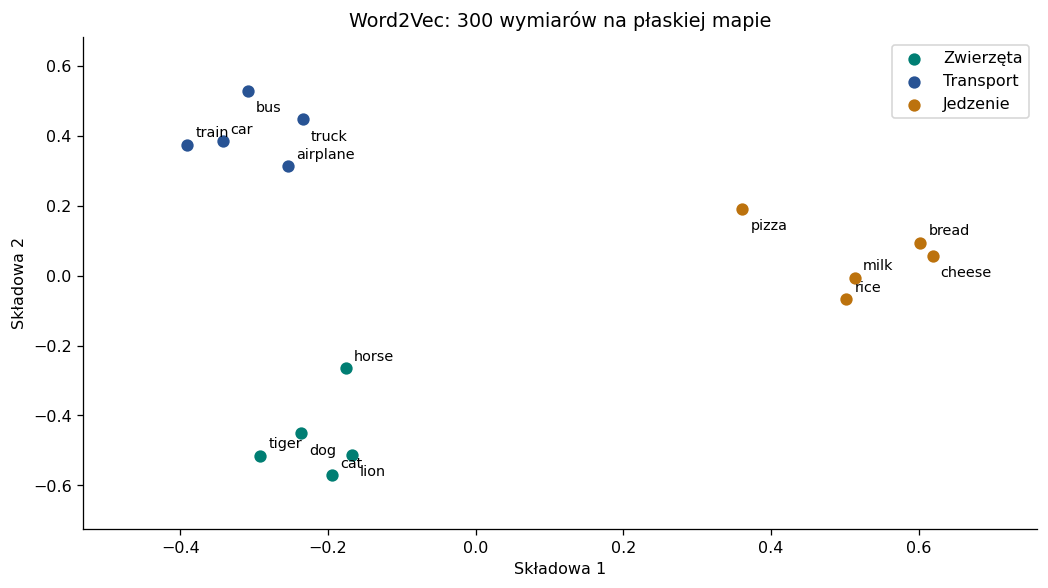

Dwie osie zachowują 38.3% wariancji wybranych wektorów.


In [13]:
# @title Zobacz grupy słów w dwóch wymiarach
from sklearn.decomposition import PCA

groups = {
    "Zwierzęta": (TEAL, ["cat", "dog", "horse", "lion", "tiger"]),
    "Transport": (BLUE, ["car", "truck", "train", "bus", "airplane"]),
    "Jedzenie": (AMBER, ["bread", "cheese", "rice", "pizza", "milk"]),
}
groups = {label: (color, [word for word in terms if word in word2vec])
          for label, (color, terms) in groups.items()}
map_words = [word for _, terms in groups.values() for word in terms]
pca = PCA(n_components=2)
points = pca.fit_transform(np.vstack([word2vec[word] for word in map_words]))
point_by_word = dict(zip(map_words, points))
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for label, (color, terms) in groups.items():
    coords = np.array([point_by_word[word] for word in terms])
    ax.scatter(*coords.T, label=label, color=color, s=45)
    for index, (word, (x, y)) in enumerate(zip(terms, coords)):
        ax.annotate(word, (x, y), xytext=(5, 5 if index % 2 == 0 else -13),
                    textcoords="offset points", fontsize=9)
ax.margins(0.14)
ax.set(xlabel="Składowa 1", ylabel="Składowa 2", title="Word2Vec: 300 wymiarów na płaskiej mapie")
ax.legend(loc="best")
plt.show()
print(f"Dwie osie zachowują {pca.explained_variance_ratio_.sum():.1%} wariancji wybranych wektorów.")

## 8. Kontekst, self-attention i kilka głów

**Slajdy 13–15.** Na slajdzie „zamek” oznacza budowlę lub mechanizm. Dla angielskich modeli użyjemy podobnej pary: `bank` jako instytucja i jako brzeg rzeki. Word2Vec odczytuje jeden wektor dla słowa `bank`. BERT oblicza oddzielną reprezentację w każdym zdaniu.

Potem odczytamy dwie prawdziwe głowy attention z pierwszej warstwy BERT-a. Każdy wiersz mapy pokazuje rozkład wag dla jednej pozycji. Wagi głowy są jednym z elementów obliczeń modelu i same nie dowodzą, dlaczego model wybrał konkretną odpowiedź.

In [14]:
# @title BERT Tiny · wczytaj wagi i porównaj reprezentacje
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

torch.set_num_threads(2)
BERT_ID = "gaunernst/bert-tiny-uncased"
BERT_REV = "acfe705a1ce159e2830c36727f99a2d4f71f5e20"

@lru_cache(maxsize=1)
def load_bert():
    tok = AutoTokenizer.from_pretrained(BERT_ID, revision=BERT_REV)
    model = AutoModelForMaskedLM.from_pretrained(
        BERT_ID, revision=BERT_REV, use_safetensors=True, attn_implementation="eager"
    ).eval()
    return tok, model

bert_tokenizer, bert = load_bert()

def contextual_bank(sentence):
    inputs = bert_tokenizer(sentence, return_tensors="pt")
    tokens = bert_tokenizer.convert_ids_to_tokens(inputs.input_ids[0].tolist())
    with torch.inference_mode():
        result = bert(**inputs, output_hidden_states=True)
    return result.hidden_states[-1][0, tokens.index("bank")].numpy()

bank_money = contextual_bank("She deposited money at the bank.")
bank_river = contextual_bank("The children sat on the bank of the river.")
if "word2vec" in globals():
    print(f"Word2Vec: ten sam wektor → cos = {word2vec.similarity('bank', 'bank'):.3f}")
else:
    print("Word2Vec: ten sam niezerowy wektor ma cos = 1.000. Sprawdź go z wagami w sekcji 6.")
bank_cosine = np.dot(bank_money, bank_river) / (np.linalg.norm(bank_money) * np.linalg.norm(bank_river))
print(f"BERT: dwa konteksty        → cos = {bank_cosine:.3f}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/32.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/528 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

Some weights of the model checkpoint at gaunernst/bert-tiny-uncased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Word2Vec: ten sam wektor → cos = 1.000
BERT: dwa konteksty        → cos = 0.870


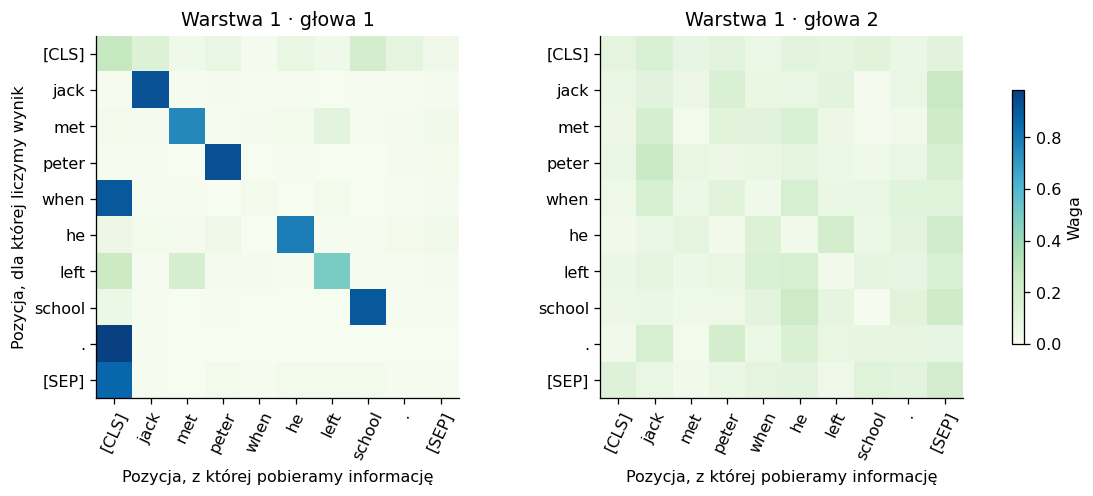

In [15]:
# @title Porównaj dwie głowy attention
attention_text = "Jack met Peter when he left school." # @param {type:"string"}
attention_inputs = bert_tokenizer(attention_text, return_tensors="pt", truncation=True, max_length=18)
attention_tokens = bert_tokenizer.convert_ids_to_tokens(attention_inputs.input_ids[0].tolist())
with torch.inference_mode():
    attention = bert(**attention_inputs, output_attentions=True).attentions[0][0].numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
for number, ax in enumerate(axes):
    heatmap = ax.imshow(attention[number], cmap="GnBu", vmin=0, vmax=attention.max())
    ax.set(xticks=range(len(attention_tokens)), yticks=range(len(attention_tokens)),
           xticklabels=attention_tokens, yticklabels=attention_tokens,
           xlabel="Pozycja, z której pobieramy informację",
           title=f"Warstwa 1 · głowa {number + 1}")
    ax.tick_params(axis="x", labelrotation=65)
axes[0].set_ylabel("Pozycja, dla której liczymy wynik")
fig.colorbar(heatmap, ax=axes, shrink=0.7, label="Waga")
plt.show()

## 9. BERT uzupełnia lukę, GPT dopisuje ciąg dalszy

**Slajdy 16–17.** Do komórki z maską uruchom najpierw „BERT Tiny” z sekcji 8 (17,7 MB). Eksperyment GPT można uruchomić samodzielnie po „Starcie” (120 MB). Zostawmy BERT-owi lewą i prawą stronę zdania. GPT dostanie sam początek i wyliczy prawdopodobieństwa następnego tokena. Do generowania użyjemy małego angielskiego modelu GPT‑2 wytrenowanego na opowiadaniach. ChatGPT to asystent oparty na modelach dodatkowo uczonych do rozmowy.

**Sprawdź:** jakie słowo BERT proponuje w zdaniu o dinozaurach? Usuń końcówkę `about dinosaurs` i porównaj listę. W GPT zmień początek opowieści i zobacz, jak zmienią się szanse kolejnych tokenów.

In [16]:
# @title BERT · top 5 uzupełnień luki
bert_example = "She read a [MASK] about dinosaurs." # @param {type:"string"}
mask_text = bert_example.replace("[MASK]", bert_tokenizer.mask_token)
mask_inputs = bert_tokenizer(mask_text, return_tensors="pt", truncation=True)
positions = (mask_inputs.input_ids[0] == bert_tokenizer.mask_token_id).nonzero().flatten()
if len(positions) != 1:
    print("Wstaw dokładnie jeden znacznik [MASK].")
else:
    with torch.inference_mode():
        probabilities = bert(**mask_inputs).logits[0, positions.item()].softmax(dim=-1)
    scores, ids = probabilities.topk(5)
    display(pd.DataFrame({"Token": bert_tokenizer.convert_ids_to_tokens(ids.tolist()),
                          "Prawdopodobieństwo": scores.tolist()}))

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


,Token,Prawdopodobieństwo
0,book,0.227
1,story,0.068
2,little,0.028
3,lot,0.024
4,mystery,0.020


In [17]:
# @title GPT · top 5 następnych tokenów i krótka kontynuacja
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

GPT_ID = "agentbyumer/TinyTale-15M"
GPT_REV = "a570a9c32311203854f8c139e27fae21f2ff9010"

@lru_cache(maxsize=1)
def load_gpt():
    tok = AutoTokenizer.from_pretrained(GPT_ID, revision=GPT_REV)
    model = AutoModelForCausalLM.from_pretrained(
        GPT_ID, revision=GPT_REV, use_safetensors=True
    ).eval()
    return tok, model

gpt_tokenizer, gpt = load_gpt()
poczatek = "Once upon a time, a small puppy found" # @param {type:"string"}
gpt_inputs = gpt_tokenizer(poczatek, return_tensors="pt", truncation=True, max_length=150)
if gpt_inputs.input_ids.shape[1] == 0:
    print("Wpisz początek opowieści.")
else:
    with torch.inference_mode():
        probabilities = gpt(**gpt_inputs).logits[0, -1].softmax(dim=-1)
        scores, ids = probabilities.topk(5)
        continuation = gpt.generate(
            **gpt_inputs, max_new_tokens=28, do_sample=False,
            pad_token_id=gpt_tokenizer.eos_token_id,
        )
    display(pd.DataFrame({
        "Token (␣ = spacja)": [gpt_tokenizer.decode([i]).replace(" ", "␣") for i in ids.tolist()],
        "Prawdopodobieństwo": scores.tolist(),
    }))
    print(gpt_tokenizer.decode(continuation[0], skip_special_tokens=True))

tokenizer_config.json:   0%|          | 0.00/339 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/863 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/120M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/211 [00:00<?, ?B/s]

,Token (␣ = spacja),Prawdopodobieństwo
0,␣a,0.902
1,␣an,0.068
2,␣the,0.006
3,␣something,0.004
4,␣it,0.002


Once upon a time, a small puppy found a big, red ball. The puppy was very happy. He wanted to play with the ball, but it was too high. The puppy


### Co model zmienia w treningu?

Miniatura jednego kroku. Ustawiamy trzy kandydatury na następny token. W tekście treningowym właściwą odpowiedzią jest `zamek`. Liczymy stratę `−ln(p)` dla tej odpowiedzi i wykonujemy jeden krok gradientu na trzech wynikach. W prawdziwym GPT wyniki powstają z parametrów wielu warstw i to te parametry aktualizuje trening.

In [18]:
# @title Zobacz zmianę prawdopodobieństw po jednym kroku
def softmax(scores):
    weights = np.exp(scores - np.max(scores))
    return weights / weights.sum()

choices = ["dom", "zamek", "kot"]
scores = np.array([1.2, 0.5, -0.3])
expected = np.array([0.0, 1.0, 0.0])
before = softmax(scores)
scores -= 0.8 * (before - expected)
after = softmax(scores)
display(pd.DataFrame({"Kandydat": choices, "Przed krokiem": before, "Po kroku": after}))
print(f"Strata: {-log(before[1]):.3f} → {-log(after[1]):.3f}")

,Kandydat,Przed krokiem,Po kroku
0,dom,0.581,0.368
1,zamek,0.289,0.514
2,kot,0.130,0.118


Strata: 1.242 → 0.665


## 10. Sentyment i sarkazm

**Slajd 18.** Ustalcie znaczenie przykładów w parach. Potem porównajcie prostą regułę, regresję logistyczną na wektorach TF‑IDF i gotowy wielojęzyczny Transformer. Regresję trenujemy na małym, napisanym do lekcji zbiorze. Poniższe zdania są osobnymi przykładami do pokazu. Wyniki z kilku zdań pozwalają omówić błędy, a ocenę jakości trzeba wykonać na większym zbiorze z etykietami. Komórka z Transformerem pobiera ok. 541 MB. Na krótszym pokazie możesz wykorzystać zapisany wynik.

In [19]:
# @title Prosta reguła i klasyfikator TF-IDF
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

training_examples = {
    "pozytywny": [
        "Świetnie działa od pierwszego dnia.", "Bardzo udany zakup.", "Obsługa jest wspaniała.",
        "Polecam, wszystko działa poprawnie.", "Jestem bardzo zadowolona.", "To naprawdę dobry produkt.",
        "Działa szybko i bez problemów.", "Fantastyczna jakość.", "Cieszę się z zakupu.",
    ],
    "negatywny": [
        "Produkt ciągle się psuje.", "Nie polecam tej usługi.", "Znowu jest awaria.",
        "Jestem rozczarowana jakością.", "Urządzenie się zepsuło.", "Obsługa była fatalna.",
        "To był bardzo zły zakup.", "Nie działa od wczoraj.", "Wciąż pojawiają się problemy.",
    ],
}
train_texts = [example for examples in training_examples.values() for example in examples]
train_labels = [label for label, examples in training_examples.items() for _ in examples]
classifier = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2)),
    LogisticRegression(max_iter=500, random_state=17),
)
classifier.fit(train_texts, train_labels)
wlasna_opinia = "Genialnie, właśnie straciłem cały zapis gry." # @param {type:"string"}
opinions = ["Świetnie, działa!", "Znowu się zepsuło.", "Świetnie, znowu się zepsuło!", wlasna_opinia]
sentiment_table = pd.DataFrame({
    "Opinia": opinions,
    "Reguła „świetnie”": ["pozytywny" if "świetnie" in words(opinion) else "brak decyzji" for opinion in opinions],
    "TF-IDF + regresja": classifier.predict(opinions),
})
display(sentiment_table)

,Opinia,Reguła „świetnie”,TF-IDF + regresja
0,"Świetnie, działa!",pozytywny,pozytywny
1,Znowu się zepsuło.,brak decyzji,negatywny
2,"Świetnie, znowu się zepsuło!",pozytywny,negatywny
3,"Genialnie, właśnie straciłem cały zapis gry.",brak decyzji,pozytywny


In [20]:
# @title Gotowy Transformer · porównaj te same polskie zdania
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SENTIMENT_ID = "tabularisai/multilingual-sentiment-analysis"
SENTIMENT_REV = "eea032081f8d247b4303ef3565e7cec1b6f201c9"

@lru_cache(maxsize=1)
def load_sentiment():
    tok = AutoTokenizer.from_pretrained(SENTIMENT_ID, revision=SENTIMENT_REV)
    model = AutoModelForSequenceClassification.from_pretrained(
        SENTIMENT_ID, revision=SENTIMENT_REV, use_safetensors=True
    ).eval()
    return tok, model

sentiment_tokenizer, sentiment_model = load_sentiment()
sentiment_inputs = sentiment_tokenizer(opinions, padding=True, truncation=True, max_length=128, return_tensors="pt")
with torch.inference_mode():
    predictions = sentiment_model(**sentiment_inputs).logits.softmax(dim=-1)
top_prob, top_id = predictions.max(dim=-1)
polish_labels = {
    "very negative": "bardzo negatywny", "negative": "negatywny", "neutral": "neutralny",
    "positive": "pozytywny", "very positive": "bardzo pozytywny",
}
labels = [sentiment_model.config.id2label[i] for i in top_id.tolist()]
display(sentiment_table.assign(
    Transformer=[polish_labels.get(label.casefold(), label) for label in labels],
    **{"Wynik modelu": top_prob.tolist()},
))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/541M [00:00<?, ?B/s]

,Opinia,Reguła „świetnie”,TF-IDF + regresja,Transformer,Wynik modelu
0,"Świetnie, działa!",pozytywny,pozytywny,bardzo pozytywny,0.514
1,Znowu się zepsuło.,brak decyzji,negatywny,negatywny,0.474
2,"Świetnie, znowu się zepsuło!",pozytywny,negatywny,bardzo pozytywny,0.554
3,"Genialnie, właśnie straciłem cały zapis gry.",brak decyzji,pozytywny,pozytywny,0.451


W zapisanym wyniku Transformer uznał sarkastyczne „Świetnie, znowu się zepsuło!” za bardzo pozytywne. Przy tej samej wypowiedzi prostszy klasyfikator wskazał ocenę negatywną. Przy opinii o utraconym zapisie gry oba modele się pomyliły.

## 11. Płynne zdanie a sprawdzalny fakt

**Slajd 19.** W zadaniu czytamy tylko dwie informacje: „Zosia ma 3 żetony, a Ola ma 5”. Oceń wypowiedzi przed uruchomieniem komórki. Czy któreś zdanie brzmi wiarygodnie, choć jego liczba jest sprzeczna z danymi?

Krótki przykład pokazuje sprawdzanie źródła na danych, które możemy w całości obejrzeć. Zdania są przygotowane do ćwiczenia.

In [21]:
# @title Zweryfikuj wynik na danych źródłowych
zetony = {"Zosia": 3, "Ola": 5}
twierdzenia = {"Razem mają 8 żetonów.": 8, "Razem mają dokładnie 9 żetonów.": 9}
display(pd.DataFrame([
    {"Twierdzenie": sentence, "Zgodne z danymi": "tak" if total == sum(zetony.values()) else "nie"}
    for sentence, total in twierdzenia.items()
]))

,Twierdzenie,Zgodne z danymi
0,Razem mają 8 żetonów.,tak
1,Razem mają dokładnie 9 żetonów.,nie


**Na koniec:** wymyśl dwa zdania, które myli Bag-of-Words. Wyjaśnij, kiedy bigramy pomagają. Następnie podaj przykład, w którym przydałby się kontekst z wcześniejszego zdania.

## Źródła i modele

- [OpenAI Cookbook · tokenizacja z tiktoken](https://developers.openai.com/cookbook/examples/how_to_count_tokens_with_tiktoken)
- [Wolne Lektury · Adam Mickiewicz, „Pan Tadeusz”](https://wolnelektury.pl/katalog/lektura/pan-tadeusz/)
- [Scikit-learn · wzór i normalizacja TF‑IDF](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting)
- [NLTK · próbka Word2Vec Google News i przykłady](https://www.nltk.org/howto/gensim.html) · [Gensim · pakiet wektorów GloVe](https://github.com/piskvorky/gensim-data) · [Artykuł o GloVe](https://aclanthology.org/D14-1162/)
- [Attention Is All You Need](https://arxiv.org/abs/1706.03762) · [Artykuł o BERT](https://aclanthology.org/N19-1423/) · [Wagi BERT Tiny](https://huggingface.co/gaunernst/bert-tiny-uncased)
- [TinyTale‑15M](https://huggingface.co/agentbyumer/TinyTale-15M) · [OpenAI · opis treningu pierwszej wersji ChatGPT](https://openai.com/index/chatgpt/)
- [TabularisAI · wielojęzyczny klasyfikator sentymentu](https://huggingface.co/tabularisai/multilingual-sentiment-analysis) · [Google Colab · import pliku .ipynb](https://research.google.com/colaboratory/faq.html#can-i-import-an-existing-jupyteripython-notebook-into-colab)